In [38]:
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.cluster import KMeans, Birch, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score, homogeneity_score, completeness_score, 
    v_measure_score, calinski_harabasz_score, davies_bouldin_score
)


# Analysis for Categorical Data

## Transforming Categorical Variables into Numerical Representations

When working with categorical variables, we need to convert them into numerical formats to make them suitable for analysis. Here are two commonly used techniques:

### 1. **One-Hot Encoding**
   - In this method, each category is transformed into a binary column. 
   - **Advantages**: 
     - Retains all the information about the categories without assuming any relationships between them.
   - **Disadvantages**:
     - If there are many categories or variables, the number of columns can grow significantly, leading to high dimensionality.

### 2. **Ordinal Encoding**
   - This method assigns an integer to each category. For example, `Red` could be represented as `1`, `Blue` as `2`, and `Green` as `3`.
   - **Advantages**:
     - Works well if there is a natural order among the categories (e.g., `Low`, `Medium`, `High`).
   - **Disadvantages**:
     - If there is no inherent order, this approach might introduce unintended biases by implying a hierarchy between categories.

Both techniques have their strengths and weaknesses. The choice between them depends on the context and the type of analysis. If high dimensionality becomes a problem with one-hot encoding, alternative methods like embeddings or distance-based approaches for categorical data might be considered.


In [39]:
df_categorical=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_categorical_features.csv',index_col=0)
df_numeric=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_numercial_features.csv',index_col=0)
df_categorical.head()

,sex,dzgroup,dzclass,income,race,ca,sfdm2,death,hospdead,diabetes,dementia
ID,,,,,,,,,,,
0,0,4,1,2,0,2,0,0,0,0,0
1,1,7,3,2,1,0,5,1,1,0,0
2,1,7,3,1,1,0,5,1,0,0,0
3,1,4,1,1,1,2,1,1,0,0,0
4,1,1,4,0,1,0,1,0,0,0,0


-We know that *dzclass* and *dzgroup* are closely related, as *dzgroup* is derived from the aggregation of *dzclass*. Therefore, we have decided to remove the *dzgroup* column to avoid redundancy.

In [40]:
df_categorical=df_categorical.drop(['dzgroup'],axis=1)
df_categorical.head()

,sex,dzclass,income,race,ca,sfdm2,death,hospdead,diabetes,dementia
ID,,,,,,,,,,
0,0,1,2,0,2,0,0,0,0,0
1,1,3,2,1,0,5,1,1,0,0
2,1,3,1,1,0,5,1,0,0,0
3,1,1,1,1,2,1,1,0,0,0
4,1,4,0,1,0,1,0,0,0,0


In [41]:
for col in df_categorical.columns:
    print(f"Column: {col}, unique values: {df_categorical[col].unique()}")

Column: sex, unique values: [0 1]
Column: dzclass, unique values: [1 3 4 2]
Column: income, unique values: [2 1 0 3 4]
Column: race, unique values: [0 1 2 3 4]
Column: ca, unique values: [2 0 1]
Column: sfdm2, unique values: [0 5 1 3 2 4]
Column: death, unique values: [0 1]
Column: hospdead, unique values: [0 1]
Column: diabetes, unique values: [0 1]
Column: dementia, unique values: [0 1]


In [42]:
df_categorical['age_category'] = pd.cut(df_numeric['age'], bins=10, labels=False)
df_categorical = pd.get_dummies(df_categorical, columns=['ca', 'sfdm2', 'race', 'dzclass'], drop_first=True)

for col in df_categorical.columns:
    if df_categorical[col].dtype == bool:
        # Convertir los valores True/False a 1/0
        df_categorical[col] = df_categorical[col].astype(int)
df_categorical.head()



,sex,income,death,hospdead,diabetes,dementia,age_category,ca_1,ca_2,sfdm2_1,...,sfdm2_3,sfdm2_4,sfdm2_5,race_1,race_2,race_3,race_4,dzclass_2,dzclass_3,dzclass_4
ID,,,,,,,,,,,,,,,,,,,,,
0,0,2,0,0,0,0,5,0,1,0,...,0,0,0,0,0,0,0,0,0,0
1,1,2,1,1,0,0,5,0,0,0,...,0,0,1,1,0,0,0,0,1,0
2,1,1,1,0,0,0,4,0,0,0,...,0,0,1,1,0,0,0,0,1,0
3,1,1,1,0,0,0,2,0,1,1,...,0,0,0,1,0,0,0,0,0,0
4,1,0,0,0,0,0,7,0,0,1,...,0,0,0,1,0,0,0,0,0,1


# Evaluation Using KMeans, Brich and GaussianMixture

In [43]:
k_values = list(range(2, 21))
# Definir una función para crear los modelos con k clusters
def models(k):
    algorithms = {
        'KMeans': KMeans(n_clusters=k),
        'Birch': Birch(n_clusters=k),
        'GaussianMixture': GaussianMixture(n_components=k)
        # No usamos el DSBCAN dado que no requiere un número de clusters
    }
    return algorithms

#Función para evaluar el rendimiento con métricas adicionales
def evaluate_clustering(algorithm, X):
    algorithm.fit(X)
    y_pred = algorithm.predict(X)
    
    # Métricas de rendimiento
    silhouette = silhouette_score(X, y_pred)
    calinski_harabasz = calinski_harabasz_score(X, y_pred)
    davies_bouldin = davies_bouldin_score(X, y_pred)
    
    return {
        'Silhouette Score': silhouette,
        'Calinski-Harabasz Index': calinski_harabasz,
        'Davies-Bouldin Index': davies_bouldin,
    }

# Evaluar los algoritmos para diferentes valores de k y para cada conjunto de etiquetas y
results_df = pd.DataFrame()


for k in k_values:
    print(f"Evaluating for k={k}")
    algorithms = models(k)  
    # Evaluar cada algoritmo para el conjunto de etiquetas y
    for name, algo in algorithms.items():
        metrics = evaluate_clustering(algo, df_categorical)
        # Crear un DataFrame para cada modelo y conjunto de resultados
        metrics['Model'] = name
        metrics['k'] = k
        # Convertir el diccionario de métricas en un DataFrame y agregarlo a los resultados
        result_row = pd.DataFrame([metrics])
        results_df = pd.concat([results_df, result_row], ignore_index=True)

# Agrupar los resultados por modelo, etiqueta y k
grouped_results = results_df.groupby(['Model', 'k']).agg({
    'Silhouette Score': 'mean',
    'Calinski-Harabasz Index': 'mean',
    'Davies-Bouldin Index': 'mean'
})

# Mostrar los resultados agrupados

Evaluating for k=2
Evaluating for k=3
Evaluating for k=4
Evaluating for k=5
Evaluating for k=6
Evaluating for k=7
Evaluating for k=8
Evaluating for k=9
Evaluating for k=10
Evaluating for k=11
Evaluating for k=12
Evaluating for k=13
Evaluating for k=14
Evaluating for k=15
Evaluating for k=16
Evaluating for k=17
Evaluating for k=18
Evaluating for k=19
Evaluating for k=20


In [44]:
grouped_results

Silhouette Score  Calinski-Harabasz Index  \
Model           k                                               
Birch           2           0.285924              2741.514170   
                3           0.122812              2305.099483   
                4           0.136263              2180.400602   
                5           0.096521              1977.064385   
                6           0.095453              1773.229211   
                7           0.089651              1621.001368   
                8           0.089899              1441.067011   
                9           0.086465              1317.071527   
                10          0.086038              1240.383035   
                11          0.084479              1167.807746   
                12          0.082531              1093.754032   
                13          0.082720              1053.774374   
                14          0.075598               995.138954   
                15          0.069303               943.861472   
                16          0.064312               903.733208   
                17          0.067072               863.441164   
                18          0.068721               831.702613   
                19          0.063626               797.484666   
                20          0.061301               766.177306   
GaussianMixture 2           0.049615               141.462328   
                3           0.036608               192.385350   
                4           0.012432               165.841319   
                5          -0.007287               153.122847   
                6          -0.005228               118.842711   
                7          -0.016368                96.944654   
                8          -0.006758               148.711996   
                9          -0.024581               149.387526   
                10         -0.051864                95.596815   
                11         -0.017890               140.369012   
                12         -0.027954               155.205426   
                13         -0.051399               122.689173   
                14         -0.004084               132.683213   
                15         -0.037309               111.851934   
                16         -0.021462               121.084980   
                17         -0.044518               120.223680   
                18         -0.041994               120.434594   
                19         -0.063668               110.642655   
                20         -0.067434                99.734563   
KMeans          2           0.279865              4223.018293   
                3           0.241283              3300.420898   
                4           0.175938              2839.331810   
                5           0.156232              2385.329103   
                6           0.147722              2216.894501   
                7           0.138061              1980.294977   
                8           0.139297              1816.523513   
                9           0.130778              1622.755109   
                10          0.125075              1553.305023   
                11          0.122014              1419.804931   
                12          0.118042              1331.942297   
                13          0.123728              1295.536880   
                14          0.124169              1216.914765   
                15          0.124635              1161.682370   
                16          0.122692              1118.559163   
                17          0.125565              1067.333052   
                18          0.126607              1051.875821   
                19          0.117315               973.828215   
                20          0.122809               958.656352   

                    Davies-Bouldin Index  
Model           k                         
Birch           2               1.252673  
                3               1.811087  
            

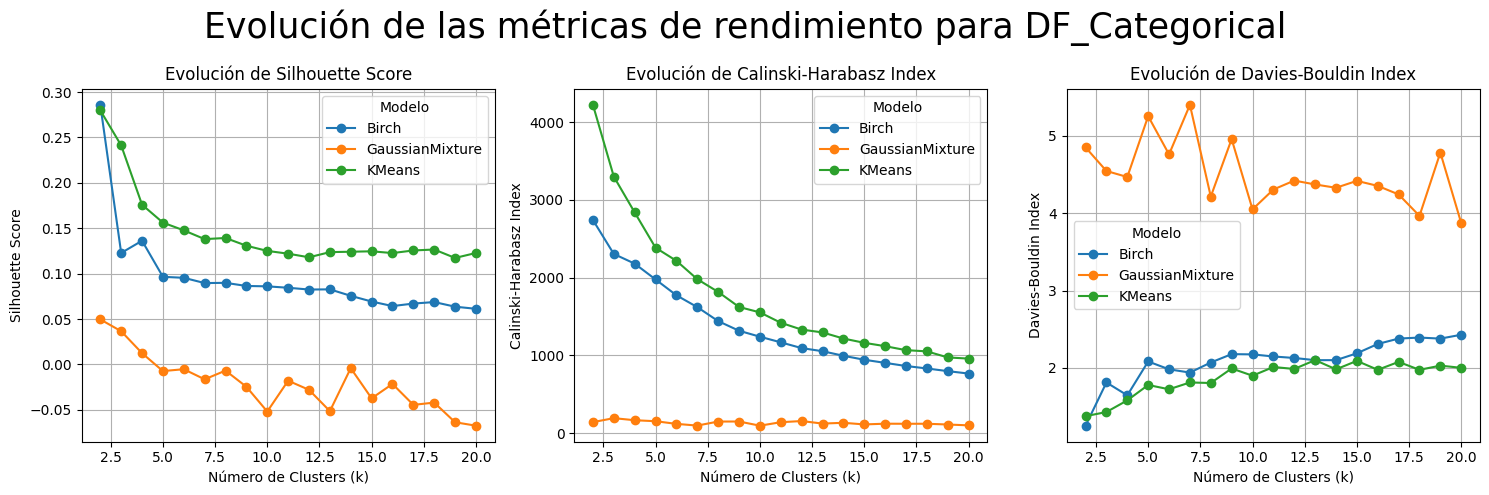

In [45]:
metrics = ["Silhouette Score",'Calinski-Harabasz Index','Davies-Bouldin Index']
# Crear un subplot para cada métrica
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True)
fig.suptitle('Evolución de las métricas de rendimiento para DF_Categorical', fontsize=25)
axes = axes.flatten()

for i, metric in enumerate(metrics):
    ax = axes[i]
    for model in grouped_results.index.get_level_values("Model").unique():
       # Filtrar datos del modelo actual
        subset = grouped_results.loc[model]
        ax.plot(subset.index, subset[metric], marker="o", label=model)
        ax.set_title(f"Evolución de {metric}")
        ax.set_xlabel("Número de Clusters (k)")
        ax.set_ylabel(metric)
        ax.legend(title="Modelo")
        ax.grid(True)


plt.tight_layout()
plt.show()

From the graphs showing the performance metrics (**Silhouette Score, Calinski-Harabasz Index and Davies-Bouldin Index**) for the **DF_Categorical** dataset, the following conclusions can be drawn by comparing the * *KMeans, Birch** and **GaussianMixture** models:

The **KMeans** model presents the best performance in all metrics. In the *Silhouette Score* (left graph), it reaches the highest values, especially when **k=2** and **k=3**, indicating better internal cohesion and separation between clusters. This is confirmed by the **Calinski-Harabasz Index** (middle graph), where KMeans obtains the highest values, highlighting a clear separation between clusters. Furthermore, the *Davies-Bouldin Index* (right graph) shows low values ​​for KMeans, around **2.0**, reflecting compact and well-separated clusters.

On the other hand, the **Birch model** has an intermediate performance. Its *Silhouette Score* remains constant around **0.1-0.15**, but without reaching the performance of KMeans. In *Calinski-Harabasz*, Birch shows acceptable values, although decreasing as **k** increases. In *Davies-Bouldin*, Birch presents values ​​between **2.0 and 2.5**, somewhat higher than KMeans, but still within an acceptable range.

The **GaussianMixture model**, on the other hand, has the lowest performance. Its *Silhouette Score* values ​​are mostly negative, indicating poor cluster assignment. In the *Calinski-Harabasz Index*, GaussianMixture maintains low values, reflecting a weak separation between clusters. Finally, in the *Davies-Bouldin Index*, it presents high values ​​(**4-5**), suggesting poorly defined and dispersed clusters.

In conclusion, **KMeans** is the most suitable model for this data set, especially with **k=2 or k=3**, followed by Birch. GaussianMixture does not achieve a good performance in any of the evaluated metrics.

# DBSCAN ANALYSIS

In [46]:
# Función para evaluar DBSCAN 
def evaluate_dbscan(epsilon, min_samples, X):
    algorithm = DBSCAN(eps=epsilon, min_samples=min_samples, metric='euclidean')
    y_pred = algorithm.fit_predict(X)
    
    # Calcular métricas
    # Verifica si hay más de un valor único en las predicciones de clúster. 
    # Si hay más de un valor (es decir, al menos dos clústeres diferentes), 
    # se calcula la métrica. Si no, se devuelve -1, indicando que la métrica no es válida o no puede ser calculada.

    silhouette = silhouette_score(X, y_pred) if len(set(y_pred)) - (1 if -1 in y_pred else 0) > 1 else -1  # el custer -1 es aquel que se asigna a los outliers
    calinski_harabasz = calinski_harabasz_score(X, y_pred) if len(set(y_pred)) - (1 if -1 in y_pred else 0) > 1 else -1
    davies_bouldin = davies_bouldin_score(X, y_pred) if len(set(y_pred)) - (1 if -1 in y_pred else 0) > 1 else -1
    
    
    # Calcular el número de clusters (excluyendo ruido -1)
    n_clusters = len(set(y_pred)) - (1 if -1 in y_pred else 0)  
    
    return {
        'Silhouette Score': silhouette,
        'Calinski-Harabasz Index': calinski_harabasz,
        'Davies-Bouldin Index': davies_bouldin,
        'n_clusters': n_clusters,  # Agregado número de clusters
        'eps': epsilon,
        'min_samples': min_samples
    }

# Evaluar DBSCAN para diferentes valores de epsilon y min_samples
eps_values = [0.1, 0.2, 0.3, 0.4, 0.5, 1.0, 1.5, 2, 2.5, 3]  # Valores de epsilon
min_samples_values = [3, 5, 10, 15, 20 ]  # Valores de min_samples

results = []


for eps in eps_values:
    for min_samples in min_samples_values:
        metrics = evaluate_dbscan(eps, min_samples, df_categorical)
        metrics['Model'] = 'DBSCAN'
        results.append(metrics)

# Convertir a DataFrame
results_df = pd.DataFrame(results)

# Agrupar resultados para resumen
grouped_results = results_df.groupby(['Model', 'eps', 'min_samples']).agg({
    'Silhouette Score': 'mean',
    'Calinski-Harabasz Index': 'mean',
    'Davies-Bouldin Index': 'mean',
    'n_clusters': 'mean'  # Promedio del número de clusters aplicado en todos los clusters dado estas combinaciones de hiperparámetros
})



In [47]:
# Mostrar los resultados con mas de un cluster
grouped_results[grouped_results['n_clusters'] > 1]

Silhouette Score  Calinski-Harabasz Index  \
Model  eps min_samples                                              
DBSCAN 0.1 3                    0.150401                 6.877968   
           5                   -0.120268                 7.779296   
           10                  -0.355903                 9.876151   
           15                  -0.412884                12.316734   
           20                  -0.347044                11.895653   
       0.2 3                    0.150401                 6.877968   
           5                   -0.120268                 7.779296   
           10                  -0.355903                 9.876151   
           15                  -0.412884                12.316734   
           20                  -0.347044                11.895653   
       0.3 3                    0.150401                 6.877968   
           5                   -0.120268                 7.779296   
           10                  -0.355903                 9.876151   
           15                  -0.412884                12.316734   
           20                  -0.347044                11.895653   
       0.4 3                    0.150401                 6.877968   
           5                   -0.120268                 7.779296   
           10                  -0.355903                 9.876151   
           15                  -0.412884                12.316734   
           20                  -0.347044                11.895653   
       0.5 3                    0.150401                 6.877968   
           5                   -0.120268                 7.779296   
           10                  -0.355903                 9.876151   
           15                  -0.412884                12.316734   
           20                  -0.347044                11.895653   
       1.0 3                   -0.353572                 8.411246   
           5                   -0.278482                19.768195   
           10                  -0.219062                40.448147   
           15                  -0.241472                58.442569   
           20                  -0.202817                76.144233   

                        Davies-Bouldin Index  n_clusters  
Model  eps min_samples                                    
DBSCAN 0.1 3                        1.205239       814.0  
           5                        1.223167       347.0  
           10                       1.286271        81.0  
           15                       1.313392        28.0  
           20                       1.391549         8.0  
       0.2 3                        1.205239       814.0  
           5                        1.223167       347.0  
           10                       1.286271        81.0  
           15                       1.313392        28.0  
           20                       1.391549         8.0  
       0.3 3                        1.205239       814.0  
           5                        1.223167       347.0  
           10                       1.286271        81.0  
           15                       1.313392        28.0  
           20                       1.391549         8.0  
       0.4 3                        1.205239       814.0  
           5                        1.223167       347.0  
           10                       1.286271        81.0  
           15                       1.313392        28.0  
           20                       1.391549         8.0  
       0.5 3                        1.205239       814.0  
           5                        1.223167       347.0  
           10                       1.286271        81.0  
           15                       1.313392        28.0  
           20                       1.391549         8.0  
       1.0 3                        1.620059        35.0  
           5                        2.470708         8.0  
           10                       2.747236         6.0  
           15                       2.723584 


Looking at the table, several conclusions can be drawn about the behavior of DBSCAN with different values ​​of *eps* and *min_samples*:

1. **Parameter variation and number of clusters:**
- For small values ​​of *eps* (between 0.1 and 0.5) and with *min_samples=3*, DBSCAN produces an extremely high number of clusters (around 814). This suggests that the density criterion is very strict, separating the dataset into many tiny clusters.
- As *min_samples* is increased while keeping *eps* small (0.1 to 0.5), the number of clusters decreases dramatically: it goes from hundreds (e.g. 814, 347, 81) to a few tens or units (28, 8). This indicates that requiring a higher minimum number of points to form a cluster reduces excessive cluster fragmentation, although at the cost of poorer quality in the separation metrics.

2. **Silhouette Score:**
- With *min_samples=3* and *eps* between 0.1 and 0.5, the *Silhouette Score* is moderately positive (~0.15), indicating some internal consistency, but considering that more than 800 clusters are generated, this might not be very significant from a practical point of view (clusters could be very small and trivial).
- As we increase *min_samples*, the *Silhouette Score* becomes negative, suggesting that the cluster structure is poor. A negative *Silhouette Score* implies that many points are closer to clusters other than their own, indicating poor separation.

3. **Calinski-Harabasz and Davies-Bouldin:**
- The Calinski-Harabasz (CH) and Davies-Bouldin (DB) indexes do not show a clear trend towards significant improvement in any parameter range.
- Generally, a lower Davies-Bouldin indicates better separation, but here the values ​​remain around 1.2 to 1.4 in cases with low *eps*, and worsen when *eps=1.0*.
- The CH Index also does not improve substantially with parameter adjustments: it reaches higher values ​​(40, 58, 76) only at the cost of forming few clusters with poor cohesion (negative Silhouette).

4. **Impact of eps=1.0:**
- By increasing *eps* to 1.0, the number of clusters is drastically reduced (between 6 and 35), but the quality metrics (negative Silhouette Score, higher Davies-Bouldin, etc.) suggest that the clustering quality does not really improve. In fact, the Silhouette gets even worse, indicating a poor cluster structure.

**Summary of the findings:**

- The results show that with small *eps* and *min_samples=3*, very numerous clusters are obtained but without a real improvement in the clustering quality in a practical sense, since hundreds of mini-clusters are created.
- Increasing *min_samples* drastically reduces the number of clusters, but worsens the internal quality metrics (negative Silhouette Score, high DB indices).
- Increasing *eps* to 1.0 does not seem to solve the problem: fewer clusters are formed but does not significantly improve the separation/cohesion metrics.
- In general, none of the tested combinations produce a particularly satisfactory result according to the presented quality metrics (Silhouette, Calinski-Harabasz, Davies-Bouldin). Other parameter ranges, data preprocessing or a different clustering method may be required to obtain more meaningful results.

# ⭐️ GENERAL CONCLUSIONS 

Of the four models, KMeans and Birch tend to outperform DBSCAN and Gaussian Mixture. Birch starts out with good quality at low K values, but its advantage fades as the number of clusters increases. KMeans, on the other hand, offers more stable and balanced performance over a wider range of K values, maintaining acceptable results across all three metrics. Thus, if one of the four methods has to be selected overall, KMeans emerges as the most consistently strong option.